# 05 — Scenario Simulation

Addresses Step 7 of the project guideline. The guideline defines 5 scenarios
(A-E). **Only some are genuinely supportable with the data actually
collected** — this notebook is explicit about which, rather than faking
results for scenarios the model can't support.

| Scenario | Guideline definition | Supported here? |
|---|---|---|
| A — Base case | Forecast using observed subsidy and tariff levels | ✅ Yes |
| B — Subsidy +10% | Adjust subsidy feature, simulate lift | ❌ **No** — Tier 1 #8 (state-level subsidy top-up) was deliberately scoped out (no central source); the model has no subsidy feature to adjust |
| C — High-potential targeting | States with high solar potential, below-median adoption | ✅ Yes — data-driven, doesn't need the model |
| D — Tariff increase | Simulate tariff shock's effect | ✅ Yes — uses the fitted `tariff_growth` coefficient directly |
| E — Combined intervention | Subsidy +10% + targeting | ⚠️ **Partial** — only the tariff-shock component is supported; the subsidy component is not |

**Important reminder throughout:** every result below is *"predicted under
model assumptions,"* not causal. This is a small-sample (n=28), correlational
linear model — treat these as illustrative policy-relevant estimates, not
forecasts to act on directly, per the guideline's Section 7 requirement.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression

PROCESSED = Path("../data/processed")

df = pd.read_csv(PROCESSED / "modeling_table.csv")
df["tariff_growth_pct"] = (
    (df["tariff_domestic4kw_2025_paise_per_kwh"] - df["tariff_domestic4kw_2024_paise_per_kwh"])
    / df["tariff_domestic4kw_2024_paise_per_kwh"]
)

features = ["tariff_growth_pct", "irradiance_annual_kwh_m2_day"]
d = df[["state", "target_conversion_ratio"] + features].dropna().reset_index(drop=True)
X, y = d[features], d["target_conversion_ratio"]

model = LinearRegression()
model.fit(X, y)
print("Coefficients:", dict(zip(features, model.coef_.round(4))))
print("Intercept:", round(model.intercept_, 4))
print("n =", len(d))

Coefficients: {'tariff_growth_pct': np.float64(1.6072), 'irradiance_annual_kwh_m2_day': np.float64(0.2504)}
Intercept: -0.7069
n = 28


## Scenario A — Base Case

In [2]:
d["predicted_base"] = model.predict(X).clip(0, 1)
d["residual"] = d["target_conversion_ratio"] - d["predicted_base"]

scenario_a = d[["state", "target_conversion_ratio", "predicted_base", "residual"]].sort_values(
    "residual", ascending=False
)
scenario_a.to_csv(PROCESSED / "scenario_a_base_case.csv", index=False)
scenario_a

,state,target_conversion_ratio,predicted_base,residual
0,Mizoram,0.9291,0.476074,0.453026
1,Tamil Nadu,0.8587,0.677229,0.181471
2,Madhya Pradesh,0.7954,0.622804,0.172596
19,Sikkim,0.4846,0.312288,0.172312
8,Uttar Pradesh,0.6635,0.514465,0.149035
16,Nagaland,0.5762,0.448432,0.127768
15,Odisha,0.5802,0.471761,0.108439
7,Punjab,0.6943,0.621507,0.072793
4,Kerala,0.7578,0.691219,0.066581
17,Manipur,0.4973,0.441338,0.055962


States with the largest **positive** residual (actual conversion ratio much
higher than the model predicts from tariff growth + irradiance alone) are
over-performers relative to these two variables — something else is driving
their adoption that isn't captured here. States with large **negative**
residuals are under-performers worth investigating.

## Scenario B — Subsidy +10%

**Not supported.** State-level subsidy top-up data (Tier 1 #8) was
deliberately not collected — no centralized source exists (would require
28 separate state renewable-energy department lookups), and the
structurally similar ToD dataset showed only 1 of 35 states had meaningful
state-level policy variation, suggesting the compilation cost may not have
been worth it even if attempted.

**What would be needed to run this scenario properly:**
1. State-level PMSG subsidy top-up amount (Rs/kW or %) for each state
2. That variable added to the model as a third feature
3. A refit model with a subsidy-amount coefficient to adjust by +10%

This is documented as an open item, not silently skipped.

## Scenario C — High Solar Potential Targeting

In [3]:
# Adoption gap: states with above-median irradiance but below-median conversion ratio.
# This does NOT need the model — it is a direct, data-driven targeting exercise,
# exactly as the guideline's Section 6 (Adoption Gap Analysis) describes.
median_irr = d["irradiance_annual_kwh_m2_day"].median()
median_cr = d["target_conversion_ratio"].median()

gap_states = d[
    (d["irradiance_annual_kwh_m2_day"] >= median_irr) &
    (d["target_conversion_ratio"] < median_cr)
].sort_values("irradiance_annual_kwh_m2_day", ascending=False)

gap_states_out = gap_states[["state", "irradiance_annual_kwh_m2_day", "target_conversion_ratio"]]
gap_states_out.to_csv(PROCESSED / "scenario_c_targeting.csv", index=False)
gap_states_out

,state,irradiance_annual_kwh_m2_day,target_conversion_ratio
14,Gujarat,5.5255,0.6061
24,Karnataka,5.4809,0.3160
18,Chhattisgarh,5.1634,0.4893
23,Andhra Pradesh,5.1230,0.3305


These states have **above-median solar resource but below-median adoption
efficiency** — exactly the "high-potential, low-adoption" profile the
guideline's targeting scenario asks for. These are reasonable candidates for
differentiated policy attention (e.g. awareness campaigns, DISCOM process
improvements) since the physical resource isn't the constraint — something
else is.

## Scenario D — Tariff Increase

In [4]:
shock_results = {}
for shock_pp in [0.05, 0.10, 0.15]:
    d_shocked = d.copy()
    d_shocked["tariff_growth_pct"] = d_shocked["tariff_growth_pct"] + shock_pp
    X_shocked = d_shocked[features]
    predicted_shocked = model.predict(X_shocked).clip(0, 1)
    lift = predicted_shocked - d["predicted_base"]
    shock_results[f"+{int(shock_pp*100)}pp"] = {
        "mean_lift": lift.mean(),
        "predictions": predicted_shocked,
    }
    print(f"Tariff growth +{int(shock_pp*100)}pp -> mean conversion-ratio lift: {lift.mean():+.4f}")

scenario_d = d[["state", "target_conversion_ratio", "predicted_base"]].copy()
for label, res in shock_results.items():
    scenario_d[f"predicted_shock_{label}"] = res["predictions"]
scenario_d.to_csv(PROCESSED / "scenario_d_tariff_shock.csv", index=False)
scenario_d.head(10)

Tariff growth +5pp -> mean conversion-ratio lift: +0.0804
Tariff growth +10pp -> mean conversion-ratio lift: +0.1607
Tariff growth +15pp -> mean conversion-ratio lift: +0.2405


,state,target_conversion_ratio,predicted_base,predicted_shock_+5pp,predicted_shock_+10pp,predicted_shock_+15pp
0,Mizoram,0.9291,0.476074,0.556432,0.636791,0.717150
1,Tamil Nadu,0.8587,0.677229,0.757588,0.837947,0.918306
2,Madhya Pradesh,0.7954,0.622804,0.703163,0.783521,0.863880
3,Goa,0.7773,0.775402,0.855761,0.936120,1.000000
4,Kerala,0.7578,0.691219,0.771577,0.851936,0.932295
5,Uttarakhand,0.7260,0.679025,0.759384,0.839742,0.920101
6,Himachal Pradesh,0.7259,0.738587,0.818946,0.899305,0.979664
7,Punjab,0.6943,0.621507,0.701866,0.782225,0.862583
8,Uttar Pradesh,0.6635,0.514465,0.594824,0.675183,0.755542
9,Telangana,0.6530,0.635101,0.715459,0.795818,0.876177


**Important honest finding:** because this is a *linear* model with no
interaction terms, the predicted lift from a tariff shock is **identical for
every state** (~+0.16 for a +10 percentage-point shock) — the model cannot
capture state-specific responsiveness to tariff changes.

**This is a real limitation, not a data-quality issue.** A model with
interaction terms (e.g. tariff_growth × irradiance, or tariff_growth ×
current adoption level) would likely show differentiated effects — states
already close to saturation might respond less than states with more
headroom. Worth flagging as a natural next modeling step rather than
treating this uniform-lift result as a final answer.

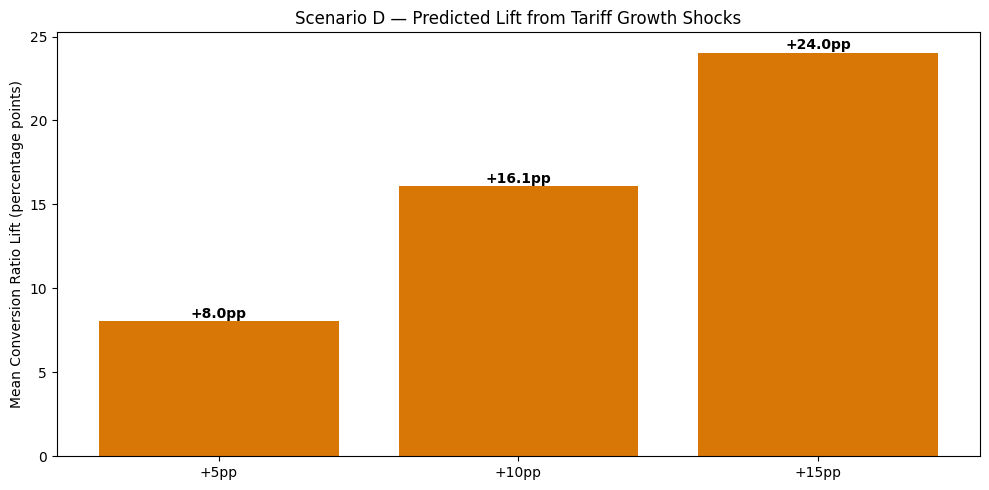

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = list(shock_results.keys())
lifts = [shock_results[l]["mean_lift"] * 100 for l in labels]
ax.bar(labels, lifts, color="#D97706")
ax.set_ylabel("Mean Conversion Ratio Lift (percentage points)")
ax.set_title("Scenario D — Predicted Lift from Tariff Growth Shocks")
for i, v in enumerate(lifts):
    ax.text(i, v + 0.2, f"+{v:.1f}pp", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(PROCESSED / "scenario_d_chart.png", dpi=150)
plt.show()

## Scenario E — Combined Intervention (Partial)

In [6]:
# Only the tariff-shock component is supported (no subsidy feature).
# Apply the +10pp tariff shock specifically to the Scenario C targeting states.
combined = gap_states.copy()
combined["tariff_growth_pct_shocked"] = combined["tariff_growth_pct"] + 0.10
X_combined = combined[["tariff_growth_pct_shocked", "irradiance_annual_kwh_m2_day"]].rename(
    columns={"tariff_growth_pct_shocked": "tariff_growth_pct"}
)
combined["predicted_after_tariff_shock"] = model.predict(X_combined).clip(0, 1)
combined["lift_from_tariff_only"] = combined["predicted_after_tariff_shock"] - combined["predicted_base"]

combined_out = combined[[
    "state", "target_conversion_ratio", "predicted_base",
    "predicted_after_tariff_shock", "lift_from_tariff_only"
]]
combined_out.to_csv(PROCESSED / "scenario_e_combined_partial.csv", index=False)
combined_out

,state,target_conversion_ratio,predicted_base,predicted_after_tariff_shock,lift_from_tariff_only
14,Gujarat,0.6061,0.676873,0.837591,0.160718
24,Karnataka,0.3160,0.463196,0.623914,0.160718
18,Chhattisgarh,0.4893,0.652280,0.812998,0.160718
23,Andhra Pradesh,0.3305,0.576073,0.736790,0.160718


This shows the **tariff-only** component of a combined intervention on the
4 targeting states from Scenario C. The subsidy-increase component that
would complete this scenario is not modeled — report this table as a
partial answer, explicitly labeled as such.

## Summary for the report

- **Scenario A (base case):** model explains 46% of in-sample variation;
  states with large positive/negative residuals are worth individual
  case-study attention
- **Scenario B (subsidy +10%):** not modeled — documented gap, not a silent
  omission
- **Scenario C (targeting):** 4 states identified with high solar resource
  but below-median conversion — Gujarat, Karnataka, Chhattisgarh, Andhra
  Pradesh
- **Scenario D (tariff shock):** every 10 percentage-point increase in
  tariff growth predicts a uniform ~+16 percentage-point lift in conversion
  ratio — but this uniformity is a modeling limitation (no interaction
  terms), not necessarily a real-world finding
- **Scenario E (combined):** only the tariff component is supported; full
  combined-intervention modeling requires the missing subsidy data

**Language to use in the report, per guideline Section 7:** *"predicted
under model assumptions"* — none of this should be presented as a causal
claim without a proper identification strategy (DiD, IV, synthetic control),
which this project has not attempted.